# Analyse exploratoire

Ce qui fait gagner un round, en six questions :

1. Certaines cartes favorisent-elles un camp ?
2. Quel est l'effet de la bombe posée ?
3. Quel est l'effet du nombre de joueurs vivants ?
4. L'argent et l'armure comptent-ils ?
5. Comment le temps restant change-t-il les chances ?
6. Quelles variables sont les plus liées à la victoire ?

Convention de couleurs : rouge = Terroristes (T), bleu = Anti-terroristes (CT).

> Une ligne correspond à un snapshot, pas à un round : les rounds longs ont plus de poids dans ces chiffres.

## 0. Imports et chargement

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from src.data import load_data
from src.eda import (add_differences, alive_matrix, time_profile,
                     top_correlations, win_rate_by, win_rate_by_bins)
from src.viz import (CMAP_WIN, COLOR_CT, COLOR_T, COLOR_TEXT, COLOR_TEXT_MUTED,
                     save_fig, set_style)

set_style()
df = add_differences(load_data())
BASE_RATE = df["t_win"].mean()
print(f"{len(df):,} lignes | taux de victoire T global : {BASE_RATE:.1%}")

122,410 lignes | taux de victoire T global : 51.0%


### Lignes impossibles : plus de 5 joueurs dans une équipe

In [2]:
anomaly = (df["t_players_alive"] > 5) | (df["ct_players_alive"] > 5)
print(f"Lignes avec plus de 5 joueurs dans une équipe : {anomaly.sum()} ({anomaly.mean():.3%})")
df.loc[anomaly, ["map", "time_left", "ct_players_alive", "t_players_alive",
                 "ct_health", "t_health", "round_winner"]].head()

Lignes avec plus de 5 joueurs dans une équipe : 1 (0.001%)


,map,time_left,ct_players_alive,t_players_alive,ct_health,t_health,round_winner
58271,de_vertigo,175.0,4.0,6.0,400.0,600.0,T


Ces lignes sont exclues des graphiques sur les joueurs vivants.

## 1. Certaines cartes favorisent-elles un camp ?

Chaque barre part de 50 % (équilibre parfait). Une barre vers la droite (rouge) = carte favorable aux T ; vers la gauche (bleu) = favorable aux CT.

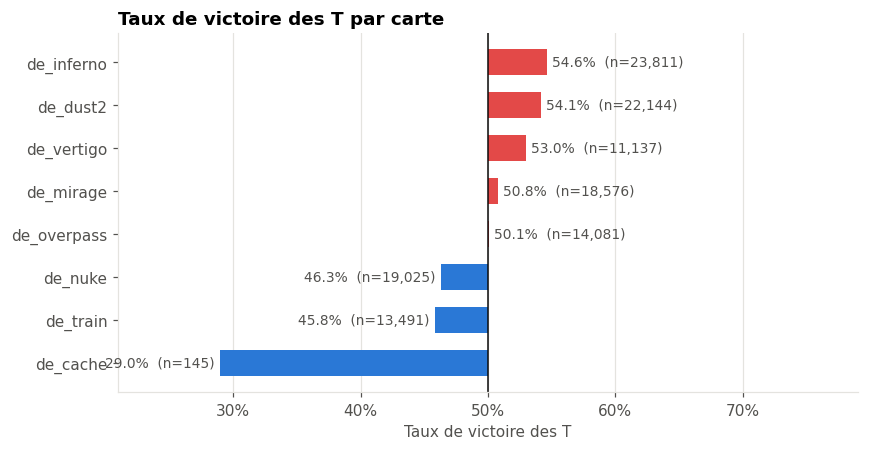

In [3]:
by_map = win_rate_by(df, "map").sort_values("t_win_rate")
by_map["ecart"] = by_map["t_win_rate"] - 0.5

fig, ax = plt.subplots(figsize=(8, 4.2))
colors = [COLOR_T if e > 0 else COLOR_CT for e in by_map["ecart"]]
ax.barh(by_map["map"].astype(str), by_map["ecart"], color=colors, height=0.6, left=0.5)
ax.axvline(0.5, color=COLOR_TEXT, linewidth=1)
for y, (rate, n) in enumerate(zip(by_map["t_win_rate"], by_map["n"])):
    ha, dx = ("left", 0.004) if rate > 0.5 else ("right", -0.004)
    ax.text(rate + dx, y, f"{rate:.1%}  (n={n:,})", va="center", ha=ha,
            fontsize=9, color=COLOR_TEXT_MUTED)
span = max(0.12, by_map["ecart"].abs().max() + 0.08)
ax.set_xlim(0.5 - span, 0.5 + span)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Taux de victoire des T")
ax.set_title("Taux de victoire des T par carte")
ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig(fig, "01_win_rate_par_carte")
plt.show()

**Conclusion :** la plupart des cartes sont proches de l'équilibre. de_inferno est la plus favorable aux T (54,6 %). de_cache affiche seulement 29,0 % de victoires T, mais ce chiffre repose sur très peu de photos (n = 145) : il n'est pas fiable.

## 2. Quel est l'effet de la bombe posée ?

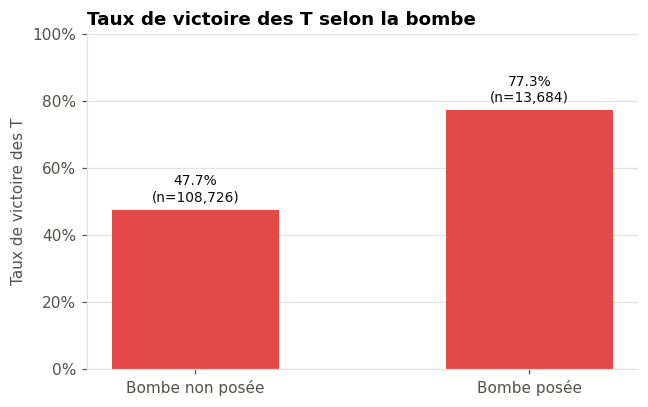

In [4]:
by_bomb = win_rate_by(df, "bomb_planted")
by_bomb["label"] = by_bomb["bomb_planted"].map({False: "Bombe non posée", True: "Bombe posée"})

fig, ax = plt.subplots(figsize=(6, 3.8))
bars = ax.bar(by_bomb["label"], by_bomb["t_win_rate"], color=COLOR_T, width=0.5)
for bar, rate, n in zip(bars, by_bomb["t_win_rate"], by_bomb["n"]):
    ax.text(bar.get_x() + bar.get_width() / 2, rate + 0.015, f"{rate:.1%}\n(n={n:,})",
            ha="center", va="bottom", fontsize=9, color=COLOR_TEXT)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_ylabel("Taux de victoire des T")
ax.set_title("Taux de victoire des T selon la bombe")
ax.grid(axis="x", visible=False)
plt.tight_layout()
save_fig(fig, "02_effet_bombe")
plt.show()

**Conclusion :** poser la bombe fait passer le taux de victoire des T de 47,7 % à 77,3 %, soit environ +30 points. C'est l'un des moments décisifs du round.

## 3. Quel est l'effet du nombre de joueurs vivants ?

Chaque case donne le taux de victoire des T pour une combinaison (joueurs CT vivants, joueurs T vivants).
Rouge = les T gagnent souvent, bleu = les CT gagnent souvent, gris = 50/50. Les cases avec moins de 100 photos sont grisées : trop peu de données pour être fiables.

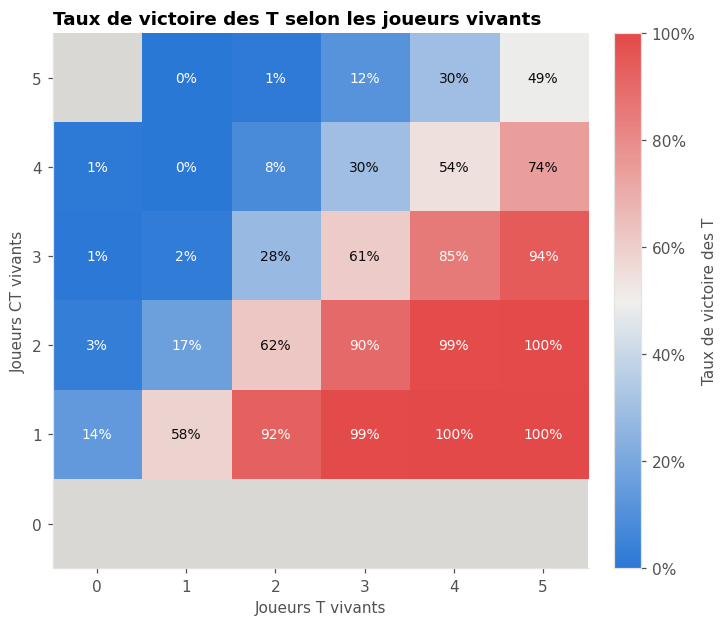

In [5]:
rates, counts = alive_matrix(df)
MIN_N = 100
shown = rates.where(counts >= MIN_N)

fig, ax = plt.subplots(figsize=(7, 5.8))
im = ax.imshow(shown.values, cmap=CMAP_WIN, vmin=0, vmax=1, origin="lower")
ax.set_facecolor("#d9d8d4")
for i, ct in enumerate(rates.index):
    for j, t in enumerate(rates.columns):
        n = counts.loc[ct, t] if t in counts.columns else np.nan
        if pd.isna(n) or n < MIN_N:
            continue
        r = rates.loc[ct, t]
        ax.text(j, i, f"{r:.0%}", ha="center", va="center", fontsize=9,
                color="white" if abs(r - 0.5) > 0.3 else COLOR_TEXT)
ax.set_xticks(range(len(rates.columns)), rates.columns)
ax.set_yticks(range(len(rates.index)), rates.index)
ax.set_xlabel("Joueurs T vivants")
ax.set_ylabel("Joueurs CT vivants")
ax.set_title("Taux de victoire des T selon les joueurs vivants")
ax.grid(False)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, format=PercentFormatter(1.0, decimals=0))
cbar.set_label("Taux de victoire des T")
plt.tight_layout()
save_fig(fig, "03_joueurs_vivants")
plt.show()

In [6]:
# Même idée, résumée par l'écart de joueurs (T - CT)
by_diff = win_rate_by(df[~anomaly], "alive_diff")
by_diff = by_diff[by_diff["n"] >= MIN_N]
by_diff[["alive_diff", "t_win_rate", "n"]].style.format({"t_win_rate": "{:.1%}", "n": "{:,}"})

,alive_diff,t_win_rate,n
1,-4.000000,0.1%,789
2,-3.000000,0.7%,"2,406"
3,-2.000000,7.5%,"5,630"
4,-1.000000,27.6%,"11,964"
5,0.000000,49.9%,"81,312"
6,1.000000,82.1%,"11,395"
7,2.000000,97.2%,"5,839"
8,3.000000,99.8%,"2,438"
9,4.000000,100.0%,607


**Conclusion :** le nombre de joueurs vivants est décisif. Avec 1 joueur d'avance, les T gagnent 82,1 % du temps ; avec 1 joueur de retard, seulement 27,6 % ; avec 2 joueurs d'avance, 97,2 %. Les cases grises « 0 CT vivant » s'expliquent par le jeu : le round est déjà terminé, donc aucune photo n'existe. Les T peuvent même gagner avec 0 joueur vivant (14 % contre 1 CT) si la bombe explose.

## 4. L'argent et l'armure comptent-ils ?

On regarde l'**écart** entre les deux équipes (T − CT). À droite de 0, les T ont plus que les CT.

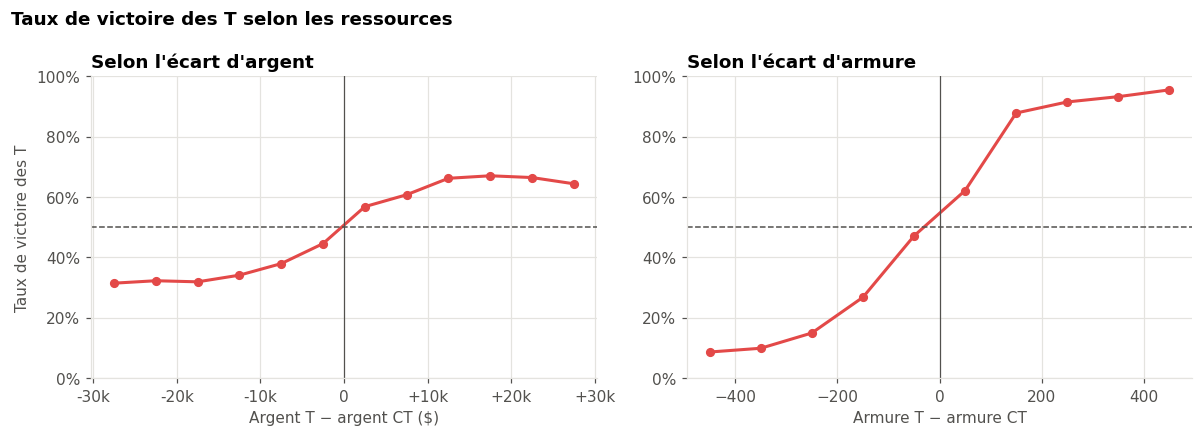

In [7]:
money_bins = list(range(-30000, 30001, 5000))
armor_bins = list(range(-500, 501, 100))
by_money = win_rate_by_bins(df, "money_diff", money_bins)
by_armor = win_rate_by_bins(df, "armor_diff", armor_bins)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, data, title, xlabel, unit in [
    (axes[0], by_money, "Selon l'écart d'argent", "Argent T − argent CT ($)", 1000),
    (axes[1], by_armor, "Selon l'écart d'armure", "Armure T − armure CT", 1),
]:
    data = data[data["n"] >= MIN_N]
    mids = data["bin"].apply(lambda iv: iv.mid).astype(float)
    ax.plot(mids, data["t_win_rate"], color=COLOR_T, linewidth=2, marker="o", markersize=5)
    ax.axhline(0.5, color=COLOR_TEXT_MUTED, linestyle="--", linewidth=1)
    ax.axvline(0, color=COLOR_TEXT_MUTED, linewidth=0.8)
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
axes[0].set_ylabel("Taux de victoire des T")
axes[0].xaxis.set_major_formatter(lambda x, _: f"{x/1000:+.0f}k" if x else "0")
fig.suptitle("Taux de victoire des T selon les ressources", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
save_fig(fig, "04_argent_armure")
plt.show()

**Conclusion :** les deux ressources favorisent l'équipe la mieux équipée, mais l'armure a l'effet le plus net : l'écart d'armure est la variable la plus corrélée à la victoire (+0,53). L'armure résume bien l'équipement réellement acheté, alors que l'argent peut ne pas encore être dépensé.

## 5. Comment le temps restant change-t-il les chances ?

**Rappel du jeu :** un round dure 1 min 55 s. Quand la bombe est posée, le chrono repart à **40 secondes**. On trace donc deux courbes séparées. L'axe est inversé : on lit de gauche (début) à droite (fin du round).

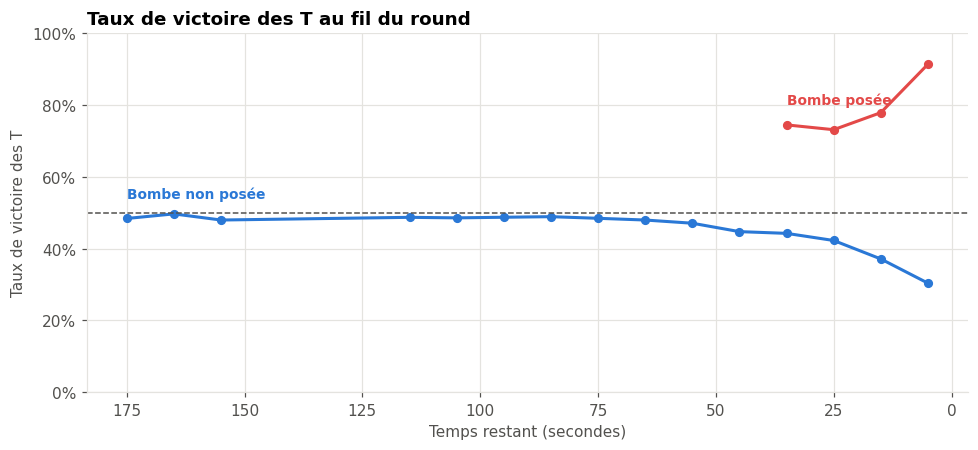

In [8]:
prof = time_profile(df, step=10)
prof = prof[prof["n"] >= MIN_N]

fig, ax = plt.subplots(figsize=(9, 4.2))
for planted, color, label in [(False, COLOR_CT, "Bombe non posée"), (True, COLOR_T, "Bombe posée")]:
    p = prof[prof["bomb_planted"] == planted].sort_values("time_mid")
    ax.plot(p["time_mid"], p["t_win_rate"], color=color, linewidth=2, marker="o", markersize=5)
    first = p.iloc[-1]  # le plus de temps restant = premier point à gauche
    ax.text(first["time_mid"], first["t_win_rate"] + 0.05, label, color=color,
            va="bottom", ha="left", fontsize=9, fontweight="bold")
ax.axhline(0.5, color=COLOR_TEXT_MUTED, linestyle="--", linewidth=1)
ax.invert_xaxis()
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Temps restant (secondes)")
ax.set_ylabel("Taux de victoire des T")
ax.set_title("Taux de victoire des T au fil du round")
plt.tight_layout()
save_fig(fig, "05_temps_restant")
plt.show()

**Conclusion :** sans bombe posée, le temps joue pour les CT : les chances des T passent d'environ 49 % en début de round à 33,7 % dans les 20 dernières secondes, car les CT gagnent si le chrono arrive à zéro. Avec la bombe posée, c'est l'inverse : les chances des T montent jusqu'à environ 91 % juste avant l'explosion.

## 6. Quelles variables sont les plus liées à la victoire ?

Corrélation de chaque variable avec `t_win`. Barre rouge = plus cette variable est grande, plus les T gagnent ; barre bleue = l'inverse.

> **Limite :** la corrélation ne voit que les liens linéaires et une variable à la fois. Elle n'est donc pas utilisée pour sélectionner les variables du modèle, contrairement à la première version du projet. Par exemple, l'effet du temps restant dépend de la bombe (section 5) : une simple corrélation ne peut pas le voir.

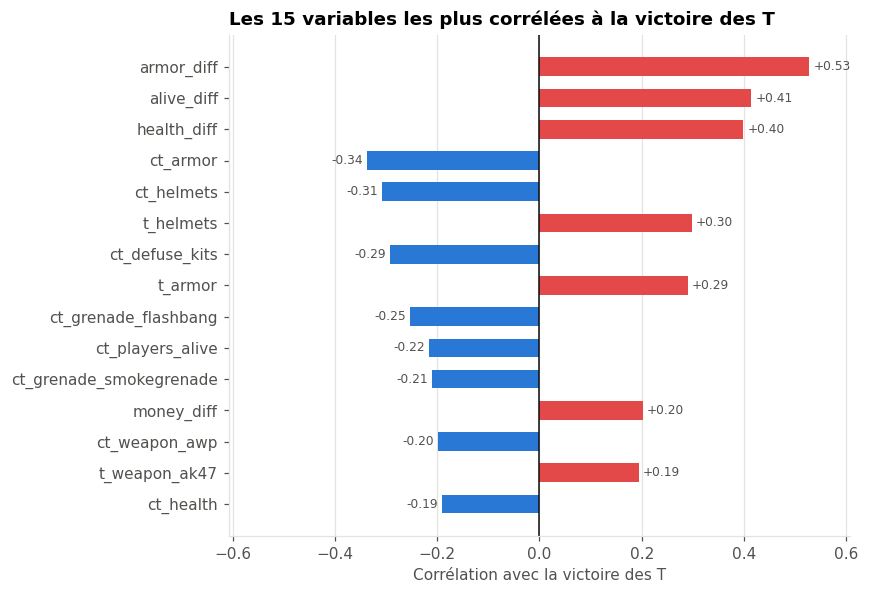

In [9]:
corr = top_correlations(df, n=15).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(corr.index, corr.values, color=[COLOR_T if v > 0 else COLOR_CT for v in corr.values], height=0.6)
ax.axvline(0, color=COLOR_TEXT, linewidth=1)
for y, v in enumerate(corr.values):
    ax.text(v + (0.008 if v > 0 else -0.008), y, f"{v:+.2f}", va="center",
            ha="left" if v > 0 else "right", fontsize=8, color=COLOR_TEXT_MUTED)
lim = corr.abs().max() + 0.08
ax.set_xlim(-lim, lim)
ax.set_xlabel("Corrélation avec la victoire des T")
ax.set_title("Les 15 variables les plus corrélées à la victoire des T")
ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig(fig, "06_correlations")
plt.show()

**Conclusion :** les variables les plus liées à la victoire sont des écarts entre équipes : `armor_diff` (+0,53), `alive_diff` (+0,41), `health_diff` (+0,40). Les écarts sont plus informatifs que les valeurs de chaque équipe prises séparément, ce qui oriente la création de variables (`04_feature_engineering.ipynb`).

## 7. Résumé des résultats

In [10]:
bomb = by_bomb.set_index("bomb_planted")["t_win_rate"]
diff = by_diff.set_index("alive_diff")["t_win_rate"]
best_t, best_ct = by_map.iloc[-1], by_map.iloc[0]
late = prof[(~prof["bomb_planted"]) & (prof["time_mid"] <= 20)]

print("=== Résumé ===")
print(f"Taux de victoire T global        : {BASE_RATE:.1%}")
print(f"Lignes à plus de 5 joueurs       : {anomaly.sum()}")
print(f"Carte la plus favorable aux T    : {best_t['map']} ({best_t['t_win_rate']:.1%})")
print(f"Carte la plus favorable aux CT   : {best_ct['map']} ({best_ct['t_win_rate']:.1%})")
print(f"T gagne, bombe non posée         : {bomb.get(False, np.nan):.1%}")
print(f"T gagne, bombe posée             : {bomb.get(True, np.nan):.1%}")
for k in [-2, -1, 0, 1, 2]:
    if k in diff.index:
        print(f"T gagne, écart de joueurs {k:+d}     : {diff[k]:.1%}")
if len(late):
    print(f"T gagne, < 20 s et bombe non posée : {late['t_win_rate'].mean():.1%}")
print("Top 5 corrélations               :", ", ".join(f"{k} ({v:+.2f})" for k, v in top_correlations(df, 5).items()))

=== Résumé ===
Taux de victoire T global        : 51.0%
Lignes à plus de 5 joueurs       : 1
Carte la plus favorable aux T    : de_inferno (54.6%)
Carte la plus favorable aux CT   : de_cache (29.0%)
T gagne, bombe non posée         : 47.7%
T gagne, bombe posée             : 77.3%
T gagne, écart de joueurs -2     : 7.5%
T gagne, écart de joueurs -1     : 27.6%
T gagne, écart de joueurs +0     : 49.9%
T gagne, écart de joueurs +1     : 82.1%
T gagne, écart de joueurs +2     : 97.2%
T gagne, < 20 s et bombe non posée : 33.7%
Top 5 corrélations               : armor_diff (+0.53), alive_diff (+0.41), health_diff (+0.40), ct_armor (-0.34), ct_helmets (-0.31)


## Conclusion

Quatre facteurs ressortent :

1. **Les joueurs vivants** : 1 joueur d'avance fait passer les T de 27,6 % à 82,1 % de victoires.
2. **La bombe posée** : +30 points pour les T (47,7 % → 77,3 %).
3. **Le temps restant**, dont l'effet **dépend de la bombe** : sans bombe, le temps favorise les CT ; avec la bombe, il favorise les T. Un modèle doit capter cette interaction.
4. **L'équipement**, surtout l'armure (corrélation +0,53).

La carte a un effet plus faible, et le chiffre de de_cache n'est pas fiable (145 snapshots seulement).

**Limite :** une ligne est un snapshot, pas un round. Plusieurs snapshots d'un même round partagent le même gagnant : ces lignes ne sont pas indépendantes, ce qui a des conséquences directes sur la façon d'évaluer un modèle (voir `03_rounds_et_fuite.ipynb`).